# 패션 이커머스 AI 어시스턴트 — 02. 추천 시스템

**이번 노트북에서 할 일**
1. 평가 방법 정하기 (마지막 구매를 맞히는 문제)
2. 베이스라인: 인기 상품 추천
3. 아이템 기반 추천: "이 상품을 산 사람이 함께 산 상품"
4. 개인화 추천: ALS (행렬 분해)
5. 세 모델 비교 + 유저 기록 길이별 비교
6. 실제 상품으로 추천 결과 눈으로 확인하기

**입력**: 01 노트북에서 저장한 `interactions_k2.parquet`, `items_k2.parquet`

> 면접에서 쓸 핵심 문장: "인기 상품 추천 대비 개인화 추천이 Recall@10 기준 몇 배 좋았고, 어떤 유저에게는 오히려 인기 추천이 나았다."

## 0. 환경 설정

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
PROJECT_DIR = '/content/drive/MyDrive/fashion-ai-assistant'
PROCESSED_DIR = f'{PROJECT_DIR}/data/processed'
MODEL_DIR = f'{PROJECT_DIR}/models'
os.makedirs(MODEL_DIR, exist_ok=True)

K = 2  # 01 노트북에서 정한 k-core 값
print(sorted(os.listdir(PROCESSED_DIR)))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
['interactions_k2.parquet', 'interactions_k3.parquet', 'items_k2.parquet', 'items_k3.parquet', 'reviews_all.parquet']


In [ ]:
!pip install -q implicit

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.sparse as sp
from sklearn.preprocessing import normalize
from IPython.display import display, HTML

pd.set_option('display.max_colwidth', 80)
TOP_N = 10

## 1. 데이터 불러오기

In [ ]:
inter_path = f'{PROCESSED_DIR}/interactions_k{K}.parquet'
items_path = f'{PROCESSED_DIR}/items_k{K}.parquet'
assert os.path.exists(inter_path), f'{inter_path} 가 없어요. 01 노트북에서 K={K}로 저장 셀을 다시 실행하세요.'

inter = pd.read_parquet(inter_path)
items = pd.read_parquet(items_path)

print(f'상호작용: {len(inter):,} | 유저: {inter.user_id.nunique():,} | 상품: {inter.parent_asin.nunique():,}')
print(f'메타데이터 상품: {len(items):,}')
inter.head()

상호작용: 289,897 | 유저: 118,869 | 상품: 70,641
메타데이터 상품: 70,641


,rating,title,text,user_id,parent_asin,timestamp,helpful_vote,verified_purchase,text_len,mentions_size
0,5,GShock Rocks!,I first saw this GShock reviewed favorably in Men's Health magazine. I ador...,AFOMGLTZZZTSOFUWHAKF2QUNXLOA,B0000C850S,2004-04-18 19:10:20,18,False,132,False
1,3,So so...,I bought this item because I dread toe shoes. But let me get to the point:<b...,AG6BLQGKWPSBB4KW7O4LFYTN4ONA,B000689EOY,2004-11-23 16:49:07,9,True,250,True
2,5,love it!!,"I have a lot of earrings and they get lost easily, so this was the perfect s...",AFLR7NVM7CNWHIQ77VV7HSY5MN4Q,B000C239IQ,2006-02-04 20:05:50,13,True,26,False
3,4,"Soft as a glove, warm and toasty!",Feb 2006:<br />I'm the type of guy who has never bothered to buy slippers. ...,AGI3EZWWHBQJAOF3UP2USMJQHIIQ,B000AS2IX4,2006-02-20 16:15:32,15,True,159,False
4,5,As pretty as shown!,These are very pretty earrings that catch the light and sparkle.,AHLGKAMK4UV42DQKAPLVM2Z75W2Q,B000BUQA2G,2006-07-26 00:15:49,0,True,11,False


## 2. 학습 / 평가 데이터 나누기 (Leave-One-Out)

유저마다 **가장 최근에 리뷰한 상품 1개를 정답으로 숨기고**, 나머지로 학습해요.
모델이 추천한 상위 10개 안에 그 정답이 들어 있으면 성공이에요.

랜덤으로 나누지 않고 시간 순서로 나누는 이유: 실제 서비스에서는 **과거 기록으로 미래 구매를 예측**해야 하니까요. 랜덤으로 나누면 미래 정보가 학습에 섞여서 점수가 부풀려집니다.

In [ ]:
inter = inter.sort_values(['user_id', 'timestamp'])
is_last = inter.groupby('user_id').cumcount(ascending=False) == 0

train_df = inter[~is_last].copy()
test_df = inter[is_last].copy()

print(f'train: {len(train_df):,} | test: {len(test_df):,} (유저 1명당 1개)')

train: 171,028 | test: 118,869 (유저 1명당 1개)


### 2-1. 유저와 상품을 숫자 번호로 바꾸기
행렬로 계산하려면 `user_id`, `parent_asin` 같은 문자열 ID를 0, 1, 2... 번호로 바꿔야 해요.

학습 데이터에 한 번도 안 나온 상품은 어떤 모델도 추천할 수 없어요. 이런 정답은 **"모델이 원천적으로 못 맞히는 경우"** 로 따로 세어 둡니다.

In [ ]:
user_ids = train_df['user_id'].unique()
item_ids = train_df['parent_asin'].unique()
user2idx = {u: i for i, u in enumerate(user_ids)}
item2idx = {a: i for i, a in enumerate(item_ids)}
idx2item = np.array(item_ids)

train_df['u'] = train_df['user_id'].map(user2idx)
train_df['i'] = train_df['parent_asin'].map(item2idx)
test_df['u'] = test_df['user_id'].map(user2idx)
test_df['i'] = test_df['parent_asin'].map(item2idx)  # 학습에 없는 상품이면 NaN

n_users, n_items = len(user_ids), len(item_ids)

# 유저 x 상품 행렬 (구매/리뷰 했으면 1)
X = sp.csr_matrix(
    (np.ones(len(train_df), dtype=np.float32), (train_df['u'], train_df['i'])),
    shape=(n_users, n_items),
)
X.data[:] = 1.0  # 혹시 중복이 있어도 1로

test_df = test_df.dropna(subset=['u']).copy()
test_df['u'] = test_df['u'].astype(int)
test_users = test_df['u'].values
test_items = test_df['i'].fillna(-1).astype(int).values  # -1 = 학습에 없는 상품

print(f'행렬 크기: {n_users:,} x {n_items:,}  (채워진 칸 {X.nnz:,})')
print(f'평가 유저: {len(test_users):,}')
print(f'정답 상품이 학습에 없는 비율: {(test_items == -1).mean():.1%}  ← 어떤 모델도 못 맞히는 몫')

행렬 크기: 118,869 x 60,541  (채워진 칸 171,028)
평가 유저: 118,869
정답 상품이 학습에 없는 비율: 19.5%  ← 어떤 모델도 못 맞히는 몫


## 3. 평가 함수

- **Recall@10**: 정답이 추천 10개 안에 들어간 유저 비율. (정답이 1개라 Hit Rate와 같아요)
- **NDCG@10**: 정답이 **몇 번째에** 있었는지까지 반영. 1등에 있으면 1점, 뒤로 갈수록 점수가 줄어요.

In [ ]:
def evaluate(recs, true_items):
    """recs: (유저 수, TOP_N) 추천 상품 번호 / true_items: (유저 수,) 정답 번호"""
    match = recs == true_items[:, None]
    hit = match.any(axis=1)
    rank = match.argmax(axis=1)
    ndcg = np.where(hit, 1.0 / np.log2(rank + 2), 0.0)
    return {'Recall@10': hit.mean(), 'NDCG@10': ndcg.mean()}

def top_n_excluding_seen(scores, users, n=TOP_N):
    """점수 행렬에서 이미 산 상품을 빼고 상위 n개 번호를 뽑는다."""
    scores = scores.copy()
    seen = X[users]
    scores[seen.nonzero()] = -np.inf
    top = np.argpartition(-scores, n, axis=1)[:, :n]
    order = np.take_along_axis(scores, top, axis=1).argsort(axis=1)[:, ::-1]
    return np.take_along_axis(top, order, axis=1)

results = {}
all_recs = {}

## 4. 베이스라인: 인기 상품 추천
모든 유저에게 학습 데이터에서 가장 많이 팔린 상품을 추천해요 (이미 산 건 제외).
**이것보다 못한 모델은 쓸 이유가 없다**는 기준선이에요.

In [ ]:
popularity = np.asarray(X.sum(axis=0)).ravel()

def recommend_popular(users):
    scores = np.tile(popularity, (len(users), 1)).astype(np.float32)
    return top_n_excluding_seen(scores, users)

BATCH = 2000
recs = np.vstack([recommend_popular(test_users[s:s + BATCH]) for s in range(0, len(test_users), BATCH)])
all_recs['Popular'] = recs
results['Popular'] = evaluate(recs, test_items)
results['Popular']

{'Recall@10': np.float64(0.01575684156508425),
 'NDCG@10': np.float64(0.008153094974371057)}

## 5. 아이템 기반 협업 필터링 (Item-based CF)

**아이디어**: 같은 사람들이 함께 산 상품끼리는 비슷하다.

1. 상품마다 "누가 샀는지"를 벡터로 표현 (행렬의 열)
2. 두 상품 벡터의 **코사인 유사도** = 구매자가 얼마나 겹치는지
3. 유저 점수 = 그 유저가 산 상품들과 비슷한 정도의 합

상품 상세 페이지의 "함께 구매한 상품" 추천이 이 원리예요.

In [ ]:
Xn = normalize(X, norm='l2', axis=0)          # 상품(열)마다 길이 1로
S = (Xn.T @ Xn).tocsr()                        # 상품 x 상품 유사도 (희소 행렬)
S.setdiag(0); S.eliminate_zeros()               # 자기 자신은 제외
print(f'유사도 행렬: {S.shape}, 0이 아닌 값 {S.nnz:,}')

def recommend_itemcf(users):
    scores = (X[users] @ S).toarray().astype(np.float32)
    # 함께 산 상품이 하나도 없어 점수가 전부 0인 경우를 대비해 인기도를 아주 작게 더해 순서를 정함
    scores += popularity[None, :] * 1e-6
    return top_n_excluding_seen(scores, users)

recs = np.vstack([recommend_itemcf(test_users[s:s + BATCH]) for s in range(0, len(test_users), BATCH)])
all_recs['ItemCF'] = recs
results['ItemCF'] = evaluate(recs, test_items)
results['ItemCF']

유사도 행렬: (60541, 60541), 0이 아닌 값 425,346


{'Recall@10': np.float64(0.016699055262515878),
 'NDCG@10': np.float64(0.008254126616843547)}

## 6. 개인화 추천: ALS (Alternating Least Squares)

**아이디어**: 유저와 상품을 각각 64차원 정도의 **취향 벡터**로 표현하고, 두 벡터의 내적이 클수록 좋아할 거라고 예측해요.
"이 유저는 미니멀 + 여성복 + 저가" 같은 숨은 취향을 데이터에서 스스로 찾아내는 방식이에요.

구매 데이터처럼 '샀다/안 샀다'만 있는 implicit feedback에 맞게 설계된 모델이라 커머스에서 많이 써요.

**주요 하이퍼파라미터**
- `factors`: 취향 벡터 차원 수
- `regularization`: 과적합 방지
- `alpha`: 구매 기록에 대한 확신도 가중치

In [ ]:
from implicit.als import AlternatingLeastSquares

als = AlternatingLeastSquares(
    factors=64,
    regularization=0.05,
    alpha=20.0,
    iterations=20,
    random_state=42,
)
als.fit(X)

def recommend_als(users):
    ids, _ = als.recommend(users, X[users], N=TOP_N, filter_already_liked_items=True)
    return ids

recs = np.vstack([recommend_als(test_users[s:s + BATCH]) for s in range(0, len(test_users), BATCH)])
all_recs['ALS'] = recs
results['ALS'] = evaluate(recs, test_items)
results['ALS']

/usr/local/lib/python3.13/dist-packages/implicit/gpu/__init__.py:28: UserWarning: Disabling GPU support because of '/usr/local/lib/python3.13/dist-packages/implicit/gpu/_cuda.so: undefined symbol: _ZN3rmm13device_bufferC1EmNS_16cuda_stream_viewENS_6detail23cccl_async_resource_refIN4cuda2mr3__412resource_refIJNS6_17device_accessibleEEEEEE'
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/implicit/cpu/als.py:96: RuntimeWarning: OpenBLAS is configured to use 48 threads. It is highly recommended to disable its internal threadpool by setting the environment variable 'OPENBLAS_NUM_THREADS=1' or by calling 'threadpoolctl.threadpool_limits(1, "blas")'. Having OpenBLAS use a threadpool can lead to severe performance issues here.
  check_blas_config()


  0%|          | 0/20 [00:00<?, ?it/s]

{'Recall@10': np.float64(0.015201608493383473),
 'NDCG@10': np.float64(0.009074682432060038)}

### 6-1. (실험) 하이퍼파라미터 바꿔보기
`factors`와 `alpha`를 바꿔서 점수가 어떻게 변하는지 보세요. 너무 오래 걸리면 후보를 줄이세요.

> 주의: 원래는 학습 / **검증** / 평가 세 개로 나눠서 검증 데이터로 튜닝해야 해요. 여기서는 공부용으로 평가 데이터를 바로 보지만, 블로그에 쓸 때는 이 한계를 같이 적어두세요.

In [ ]:
tuning = []
for factors in [32, 64, 128]:
    for alpha in [5.0, 20.0, 40.0]:
        m = AlternatingLeastSquares(factors=factors, regularization=0.05, alpha=alpha,
                                    iterations=15, random_state=42)
        m.fit(X, show_progress=False)
        r = np.vstack([m.recommend(test_users[s:s + BATCH], X[test_users[s:s + BATCH]],
                                   N=TOP_N, filter_already_liked_items=True)[0]
                       for s in range(0, len(test_users), BATCH)])
        tuning.append({'factors': factors, 'alpha': alpha, **evaluate(r, test_items)})

pd.DataFrame(tuning).sort_values('Recall@10', ascending=False).round(4)

,factors,alpha,Recall@10,NDCG@10
8,128,40.0,0.0156,0.0098
5,64,40.0,0.0154,0.0093
4,64,20.0,0.0149,0.0088
1,32,20.0,0.0143,0.0084
7,128,20.0,0.0140,0.0088
2,32,40.0,0.0137,0.0079
3,64,5.0,0.0133,0.0080
0,32,5.0,0.0132,0.0078
6,128,5.0,0.0130,0.0081


## 7. 모델 비교

In [ ]:
res = pd.DataFrame(results).T
res['vs Popular'] = (res['Recall@10'] / res.loc['Popular', 'Recall@10']).round(2).astype(str) + 'x'
upper = 1 - (test_items == -1).mean()
print(f'참고: 학습에 없는 정답 때문에 Recall@10의 이론상 최대값은 {upper:.1%}')
res.round(4)

참고: 학습에 없는 정답 때문에 Recall@10의 이론상 최대값은 80.5%


,Recall@10,NDCG@10,vs Popular
Popular,0.0158,0.0082,1.0x
ItemCF,0.0167,0.0083,1.06x
ALS,0.0152,0.0091,0.96x


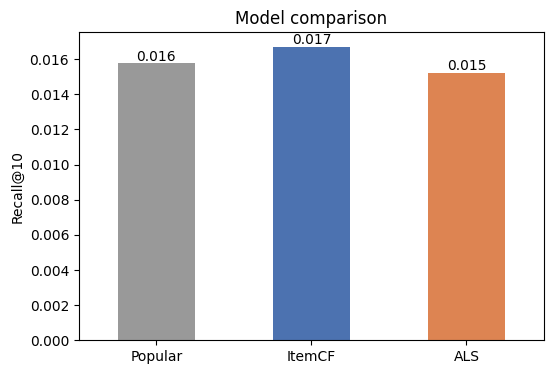

In [ ]:
fig, ax = plt.subplots(figsize=(6, 4))
res['Recall@10'].plot.bar(ax=ax, color=['#999999', '#4C72B0', '#DD8452'])
ax.set_ylabel('Recall@10'); ax.set_title('Model comparison')
ax.tick_params(axis='x', rotation=0)
for p in ax.patches:
    ax.annotate(f'{p.get_height():.3f}', (p.get_x() + p.get_width() / 2, p.get_height()),
                ha='center', va='bottom')
plt.show()

### 7-1. 유저 기록 길이별 비교
01 노트북 정리 질문 1번("기록이 적은 유저는 인기 추천, 많은 유저는 개인화")을 **데이터로 검증**하는 부분이에요.
여기서 나온 결과가 포트폴리오에서 가장 좋은 이야기거리가 됩니다.

In [ ]:
hist_len = np.asarray(X[test_users].sum(axis=1)).ravel()
bins = pd.cut(hist_len, bins=[0, 1, 2, 4, 9, np.inf], labels=['1', '2', '3-4', '5-9', '10+'])

rows = []
for name, recs in all_recs.items():
    hit = (recs == test_items[:, None]).any(axis=1)
    for b in bins.categories:
        mask = np.asarray(bins == b)
        rows.append({'model': name, 'train 기록 수': b, 'users': mask.sum(), 'Recall@10': hit[mask].mean()})

seg = (pd.DataFrame(rows)
         .pivot(index='train 기록 수', columns='model', values='Recall@10')
         .reindex(bins.categories))
seg['users'] = pd.Series(np.asarray(bins)).value_counts().reindex(bins.categories).fillna(0).astype(int)
seg = seg[seg['users'] > 0]
seg.round(4)

model,ALS,ItemCF,Popular,users
1,0.0147,0.0175,0.0166,92237
2,0.0159,0.0145,0.0131,17206
3-4,0.0191,0.0127,0.0140,6929
5-9,0.0193,0.0117,0.0107,1968
10+,0.0132,0.0132,0.0000,529


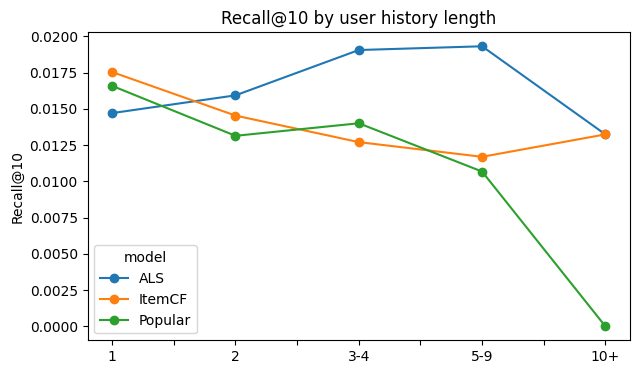

In [ ]:
seg.drop(columns='users').plot(marker='o', figsize=(7, 4))
plt.ylabel('Recall@10'); plt.title('Recall@10 by user history length')
plt.show()

In [ ]:
print('=== 7. 모델 비교 ===')
print(f'Recall@10 이론상 최대값: {1 - (test_items == -1).mean():.1%}')
print(res.round(4).to_string())

print('\n=== 7-1. 기록 길이별 비교 ===')
print(seg.round(4).to_string())

print('\n=== 6-1. 하이퍼파라미터 ===')
print(pd.DataFrame(tuning).sort_values('Recall@10', ascending=False).round(4).to_string())

=== 7. 모델 비교 ===
Recall@10 이론상 최대값: 80.5%
         Recall@10  NDCG@10 vs Popular
Popular     0.0158   0.0082       1.0x
ItemCF      0.0167   0.0083      1.06x
ALS         0.0152   0.0091      0.96x

=== 7-1. 기록 길이별 비교 ===
model     ALS  ItemCF  Popular  users
1      0.0147  0.0175   0.0166  92237
2      0.0159  0.0145   0.0131  17206
3-4    0.0191  0.0127   0.0140   6929
5-9    0.0193  0.0117   0.0107   1968
10+    0.0132  0.0132   0.0000    529

=== 6-1. 하이퍼파라미터 ===
   factors  alpha  Recall@10  NDCG@10
8      128   40.0     0.0156   0.0098
5       64   40.0     0.0154   0.0093
4       64   20.0     0.0149   0.0088
1       32   20.0     0.0143   0.0084
7      128   20.0     0.0140   0.0088
2       32   40.0     0.0137   0.0079
3       64    5.0     0.0133   0.0080
0       32    5.0     0.0132   0.0078
6      128    5.0     0.0130   0.0081


## 8. 추천 결과 눈으로 확인하기
숫자만 보면 놓치는 게 많아요. 실제 상품명과 이미지로 "말이 되는 추천인지" 확인해 보세요.

In [ ]:
item_info = items.set_index('parent_asin')

def show_items(asins, title):
    cards = []
    for a in asins:
        row = item_info.loc[a] if a in item_info.index else None
        name = (row['title'] if row is not None and row['title'] else a)[:60]
        img = row['image_url'] if row is not None and row['image_url'] else ''
        img_tag = f'<img src="{img}" style="height:110px;object-fit:contain">' if img else '<div style="height:110px">no image</div>'
        cards.append(f'<div style="width:130px;font-size:11px;text-align:center">{img_tag}<br>{name}</div>')
    display(HTML(f'<h4>{title}</h4><div style="display:flex;gap:8px;flex-wrap:wrap">{"".join(cards)}</div>'))

def inspect_user(pos):
    u = test_users[pos]
    bought = idx2item[X[u].indices]
    truth = idx2item[test_items[pos]] if test_items[pos] >= 0 else '(학습에 없는 상품)'
    show_items(bought, '학습 기간에 산 상품')
    show_items([truth] if test_items[pos] >= 0 else [], f'정답 (실제로 다음에 산 상품): {truth}')
    for name, recs in all_recs.items():
        hit = '  ✅ 적중' if test_items[pos] in recs[pos] else ''
        show_items(idx2item[recs[pos]], f'{name} 추천{hit}')

# 기록이 5개 이상인 유저 중 하나를 랜덤으로
rng = np.random.default_rng(0)
candidates = np.where(hist_len >= 5)[0]
inspect_user(rng.choice(candidates))

### 8-1. 비슷한 상품 찾기 (상품 상세 페이지용)

In [ ]:
def similar_items(asin, n=8):
    i = item2idx[asin]
    cf_sim = S[i].toarray().ravel()
    cf_top = idx2item[np.argsort(-cf_sim)[:n]]
    als_ids, _ = als.similar_items(i, N=n + 1)
    als_top = idx2item[[j for j in als_ids if j != i][:n]]
    show_items([asin], '기준 상품')
    show_items(cf_top, 'ItemCF: 함께 구매한 상품')
    show_items(als_top, 'ALS: 취향이 비슷한 상품')

# 인기 상품 중 하나로 확인 (asin을 직접 넣어봐도 돼요)
similar_items(idx2item[np.argsort(-popularity)[5]])

## 9. 저장
다음 단계(검색, 챗봇)에서 추천 결과를 같이 쓰기 위해 모델과 결과를 저장해요.

In [ ]:
import pickle

res.to_csv(f'{MODEL_DIR}/rec_results_k{K}.csv')
seg.to_csv(f'{MODEL_DIR}/rec_by_history_k{K}.csv')

np.save(f'{MODEL_DIR}/als_item_factors.npy', als.item_factors)
np.save(f'{MODEL_DIR}/als_user_factors.npy', als.user_factors)
sp.save_npz(f'{MODEL_DIR}/itemcf_similarity.npz', S)
with open(f'{MODEL_DIR}/id_maps.pkl', 'wb') as f:
    pickle.dump({'user_ids': user_ids, 'item_ids': item_ids, 'popularity': popularity}, f)

print(sorted(os.listdir(MODEL_DIR)))

['als_item_factors.npy', 'als_user_factors.npy', 'id_maps.pkl', 'itemcf_similarity.npz', 'rec_by_history_k2.csv', 'rec_results_k2.csv']


## 10. 정리해볼 질문 (블로그 / 포트폴리오용)

1. 세 모델의 Recall@10은? ALS는 인기 추천보다 몇 배 좋았나?

세 모델의 Recall@10은 인기 추천 [1.58%], ItemCF [ 1.67%], ALS [1.52% ]였다. ALS는 인기 추천보다 [ 0.96]배 낮았다. NDCG@10도 [같은 순서였다 / 순서가 달랐다].

(ALS가 가장 좋았다면)

유저의 구매 기록 전체에서 숨은 취향을 학습하는 ALS가 가장 좋았다. 같은 상품을 함께 산 기록만 보는 ItemCF와 달리, 직접 겹치는 구매가 없어도 비슷한 취향의 상품을 찾을 수 있기 때문으로 보인다.

(인기 추천이나 ItemCF가 ALS보다 좋았다면)

개인화 모델인 ALS가 오히려 단순한 방법보다 낮았다. 유저의 85.3%가 리뷰를 1개만 남긴 극도로 희소한 데이터라, ALS가 유저의 취향 벡터를 학습할 근거가 부족했던 것으로 보인다. "복잡한 모델이 항상 낫지 않다"는 것을 확인했고, 베이스라인을 먼저 세운 이유가 여기에 있다.

참고로 절대 점수가 낮아 보여도 괜찮아요. 상품이 7만 개 넘는 상황에서 10개 안에 정답 1개를 맞히는 문제라, 몇 %만 나와도 무작위 추천(10/70,000 ≈ 0.01%)보다 수백 배 높은 거예요. 이 비교를 한 줄 넣으면 숫자가 훨씬 설득력 있어져요.

2. 정답 상품이 학습 데이터에 없는 비율은? 이게 점수의 상한을 어떻게 제한하나? 어떻게 대응할까?

정답 상품이 학습 데이터에 한 번도 등장하지 않은 경우가 [ 19.5]%였다. 협업 필터링은 다른 유저의 구매 기록으로 상품을 학습하기 때문에, 학습 데이터에 없는 상품은 어떤 모델도 추천할 수 없다. 따라서 Recall@10의 이론상 최대값은 [ 80.5]%다.

이는 신상품이 계속 들어오는 패션 커머스에서 특히 중요한 문제다(아이템 콜드 스타트). 구매 기록이 없는 상품은 상품명, 설명, 이미지 같은 콘텐츠 정보로 대응해야 한다. 3단계 의미 검색에서 만들 상품 임베딩을 활용하면, 신상품도 "기존에 잘 팔린 상품과 내용이 비슷한 상품"으로 추천할 수 있다.

3. 기록이 1개인 유저에게 가장 좋은 모델은? 기록이 많아질수록 순위가 바뀌나?

학습 기록이 1개인 유저에서는 [ ItemCF]가 Recall@10 [ 1.75%]로 가장 좋았고, 기록이 [ 2]개 이상인 구간부터는 [ ALS]가 가장 좋았다.

(기록이 늘수록 ALS가 역전했다면)

01에서 세운 "기록이 적은 유저는 인기 추천, 많은 유저는 개인화" 전략이 데이터로 확인됐다. 실제 서비스라면 유저의 기록 수에 따라 모델을 다르게 쓰는 방식(하이브리드)이 하나의 모델만 쓰는 것보다 낫다.

(모든 구간에서 같은 모델이 1등이었다면)

01에서 예상한 "기록이 많아지면 개인화가 앞선다"는 전략은 이 데이터에서는 확인되지 않았다. 다만 기록이 10개 이상인 유저 수가 [ 529]명으로 적어서, 활동이 많은 유저 구간에서는 결론을 내리기 어렵다. 예상과 다른 결과를 그대로 기록하고, 데이터가 충분한 환경에서 다시 검증할 과제로 남긴다.

각 구간의 users 숫자도 같이 적으세요. 유저 수가 수십 명밖에 안 되는 구간은 점수가 우연히 높거나 낮을 수 있어서, 그 구간으로 결론을 내리면 안 된다는 점을 보여주는 근거가 돼요.

4. "점수는 맞혔는데 이상한 추천" 또는 "못 맞혔지만 괜찮은 추천"이 있었나?

이건 직접 보고 쓰는 질문이라 정답이 없어요. inspect_user 셀을 여러 번 실행해서 유저 3~5명 정도 보고, 아래 같은 패턴이 있는지 찾아보세요.

못 맞혔지만 괜찮은 추천: 정답은 검정 원피스인데 추천에 비슷한 스타일 원피스가 여러 개 있는 경우. 지표상으로는 실패지만 실제로는 좋은 추천이에요.
맞혔지만 아쉬운 추천: 인기 추천이 맞혔는데 추천 10개가 모든 유저에게 똑같은 경우. 개인화가 전혀 안 된 거예요.
이상한 추천: 여성복만 산 유저에게 남성 신발이 추천되는 경우.

예시 문장은 이렇게 쓸 수 있어요.

한 유저는 [ 고급진 반지,시계,가방,넥타이] 같은 상품을 샀고 정답은 [고급진 보석이 박힌 목걸이 ]였다. ALS는 정답을 못 맞혔지만, 추천 목록에 비슷한 [스타일/카테고리] 상품이 [ 1]개 있어서 실제로는 괜찮은 추천이었다. 이처럼 Recall@10은 정확히 같은 상품을 맞혔는지만 보기 때문에 추천 품질을 다 보여주지 못한다. 실무에서 오프라인 지표와 함께 A/B 테스트로 실제 클릭과 구매를 확인하는 이유다.

이 마지막 두 문장이 면접에서 특히 좋은 포인트예요. "지표의 한계를 안다"는 걸 보여주니까요.

5. ItemCF와 ALS의 '비슷한 상품'은 어떻게 달랐나? 각각 어디에 쓰면 좋을까?

결과를 보고 차이를 한 줄로 적은 다음, 아래 내용을 이어 쓰면 돼요.

ItemCF는 [실제로 같은 사람이 함께 산 상품, 예를 들어 같은 브랜드나 세트 상품]이 주로 나왔고, ALS는 [직접 함께 산 기록은 없어도 분위기나 카테고리가 비슷한 상품]이 더 다양하게 나왔다.

ItemCF는 "실제로 함께 구매됐다"는 직접적인 근거가 있어서 결과를 설명하기 쉽다. 그래서 상품 상세 페이지의 "이 상품을 산 고객이 함께 구매한 상품" 이나 장바구니의 "함께 사면 좋은 상품" 에 적합하다.

ALS는 숨은 취향을 기준으로 찾기 때문에 직접적인 구매 연결이 없어도 비슷한 상품을 찾을 수 있다. 대신 왜 추천됐는지 설명하기 어렵다. 그래서 홈 화면의 "당신을 위한 추천" 처럼 탐색과 발견이 목적인 곳에 적합하다.



6. "점수는 맞혔는데 이상한 추천" 또는 "못 맞혔지만 괜찮은 추천"이 있었나?

한 유저 사례를 직접 확인했다. 이 유저는 학습 기간에 실버 원석 반지 3개(터키석, 오닉스, 문스톤), 가죽 벨트, 여성 손목시계, 마이클 코어스 토트백을 샀고, 실제로 다음에 산 상품은 라피스 라줄리 원석 펜던트 목걸이였다. 세 모델 모두 정답을 맞히지 못했지만, 추천의 질은 크게 달랐다.

ItemCF (못 맞혔지만 괜찮은 추천): 추천 10개 중 8개가 실버 원석 반지, 귀걸이, 펜던트였다. 유저의 "실버 원석 주얼리" 취향을 정확히 잡았고, 해마 펜던트처럼 정답과 같은 종류(펜던트 목걸이)도 있었다. 지표상으로는 실패지만 실제 서비스였다면 클릭이나 구매로 이어졌을 가능성이 높은 추천이다.
인기 추천: 후드티, 레깅스, 남성 운동용 탱크톱, LED 손가락 조명처럼 유저 취향과 상관없는 상품이 대부분이었다. 모든 유저에게 거의 같은 목록이 나가기 때문에 개인화가 전혀 되지 않는다.
ALS (이상한 추천): 반다나, 기도용 숄, 여아용 원피스, 남성 탱크톱처럼 이 유저와 맞지 않는 상품이 섞여 있었다. 인기 추천에도 나온 은 광택천과 여성 탱크톱이 포함된 것으로 보아, 학습 기록이 적은 상품은 취향 벡터가 제대로 학습되지 않아 인기 상품 쪽으로 쏠린 것으로 보인다.

또 하나 발견한 문제는 사실상 같은 상품의 중복 추천이다. ItemCF가 추천한 “Chuvora 925 실버 문스톤 반지”와 “925 실버 블랙 오닉스 반지”는 유저가 이미 산 상품과 이름과 사진이 거의 같았다. 판매자가 같은 상품을 다른 상품 ID로 여러 번 등록한 것으로 보이며, 이미 산 상품을 제외하는 필터를 상품 ID 기준으로만 걸어서 걸러지지 않았다. 실제 서비스라면 상품명이나 이미지 유사도로 중복 상품을 묶는 처리가 필요하다.

이처럼 Recall@10은 정확히 같은 상품을 맞혔는지만 보기 때문에, 취향을 잘 잡은 추천과 엉뚱한 추천을 구분하지 못한다. 실무에서 오프라인 지표와 함께 추천 결과를 직접 확인하고, A/B 테스트로 실제 클릭과 구매를 측정하는 이유다.

7. ItemCF와 ALS의 '비슷한 상품'은 어떻게 달랐나? 각각 어디에 쓰면 좋을까?

이건 제가 미리 써드렸던 예상(“ItemCF는 세트 상품, ALS는 분위기가 비슷한 상품”)과 실제 결과가 달랐어요. 실제 결과대로 바꿔 적으세요.

카시오 F91W 디지털 시계를 기준으로 비슷한 상품 8개를 비교했다.

ItemCF: 아동용 블레이저, LED 신발 조명, 사이클 저지, 위장 무늬 양말, 신발끈, 셔츠 고정 밴드 등 카테고리가 제각각이었다. 시계는 1개뿐이었다.
ALS: 남성 손목시계 3개(파슬, 밀리터리 시계, 그린 다이얼 시계)가 포함돼 시계라는 카테고리를 더 잘 잡았다. 다만 아기 부츠, 여성 원피스처럼 관계없는 상품도 섞여 있었다.

두 결과에 아동 블레이저, 선글라스 세트, 신발끈, 파슬 시계가 공통으로 나온 것을 보면, 이 상품들은 소수의 같은 유저가 함께 리뷰한 상품으로 보인다. 데이터가 희소해서 구매자 한두 명의 기록이 유사도를 좌우했다. ItemCF는 이런 우연한 함께 구매를 그대로 반영하고, ALS는 전체 구매 패턴을 압축하는 과정에서 이 잡음을 조금 걸러낸 것으로 해석했다.

정리하면, ItemCF는 "실제로 함께 구매됐다"는 설명하기 쉬운 근거가 있지만, 함께 구매한 유저가 충분히 많을 때만 믿을 수 있다. 그래서 구매 기록이 많은 상품의 "함께 구매한 상품" 영역에 쓰고, 최소 함께 구매 횟수 같은 기준을 두는 게 좋다. ALS는 잡음에 조금 더 강해서 "비슷한 상품" 이나 홈 화면 개인화 추천에 적합하다.

하지만 두 방법 모두 "디지털 시계와 비슷한 상품"이라는 직관적인 기대에는 못 미쳤다. 구매 기록만으로는 상품이 무엇인지 알 수 없기 때문이다. 상품명, 설명, 이미지 같은 콘텐츠 정보를 쓰는 3단계 의미 검색이 필요한 이유를 여기서 확인했다.